# Post - model FIP bias analysis

Will load the avergae spectra and their 25th, 75th percentile and calculate the average FIP bias corresponding

## Loas necessary packages

In [1]:
import sys
import os

parent_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))
sys.path.append(parent_dir)
parent_dir1 = os.path.abspath(os.path.join(parent_dir, '..'))
sys.path.append(parent_dir1)

import numpy as np
import matplotlib.pyplot as plt
import simspice.utils.FIP_bias_computation as FIP
import pandas as pd
from tqdm.auto import tqdm

simspice = "/d0/tvaresano/SimSPICE/"

/d0/tvaresano/.conda/envs/simspice/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load average spectra

In [2]:
data = np.load(f"{simspice}notebooks/average_spectra/cluster_spectra_300_20_Simsiam_two_ch_norm_40epoch_17Nov2026.npz")

cluster_ids = data["cluster_ids"]
wvl = data["wavelength"]

mean_spectra = data["mean"]
p25_spectra = data["p25"]
p75_spectra = data["p75"]

print(mean_spectra.shape)
print(p25_spectra.shape)
print(p75_spectra.shape)

(5, 121)
(5, 121)
(5, 121)


## Define fit parameters

In [3]:
fit_parameters = {'O III 703 / Mg IX 706 (Merged)': dict(mean=702.8, mean1=703.8, mean2=706, sep1=703.2, sep2=705),
    'Ne VIII 770 (Merged)':  dict(mean=770.4, mean1=772.3, sep1=771.5),
    'S V 786 / O IV 787 (Merged)':  dict(mean=786.2, mean1=787.6, sep1=787.0),}

In [22]:
from pathlib import Path

plot_dir = Path("fit_plots")
plot_dir.mkdir(exist_ok=True)

SHOW_PLOTS = True  # Set True to display every fit


def plot_spectral_fit(wvl, flux, results, cluster_id, spec_type, line,
                      save_path=None):

    x = np.asarray(wvl)
    y = np.asarray(flux)

    fig, ax = plt.subplots(figsize=(9, 5))

    # Observed spectrum
    ax.plot(x, y, "k.", markersize=5, label="Observed")
    ax.plot(x, y, "k-", alpha=0.35)

    # Background (assumed shared across components)
    background = float(results[0].get("background", 0.0))

    total_model = np.full_like(x, background, dtype=float)

    # Individual Gaussian components
    for j, result in enumerate(results):

        amplitude = float(result["amplitude"])
        mean = float(result["mean"])
        std = float(result["std"])

        gaussian = amplitude * np.exp(-0.5 * ((x - mean) / std)**2)

        total_model += gaussian

        ax.plot(x, gaussian + background, "--", alpha=0.7, label=f"Component {j+1}")

    # Total fitted spectrum
    ax.plot(x,total_model, "r-", linewidth=2,
        label="Total fit")

    ax.set_xlabel("Wavelength")
    ax.set_ylabel("Intensity")
    ax.set_title(f"Cluster {cluster_id} | {spec_type} | {line}")

    ax.legend()
    ax.grid(alpha=0.25)

    fig.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")

    if SHOW_PLOTS:
        plt.show()

    plt.close(fig)

mean:   0%|          | 0/5 [00:00<?, ?it/s]

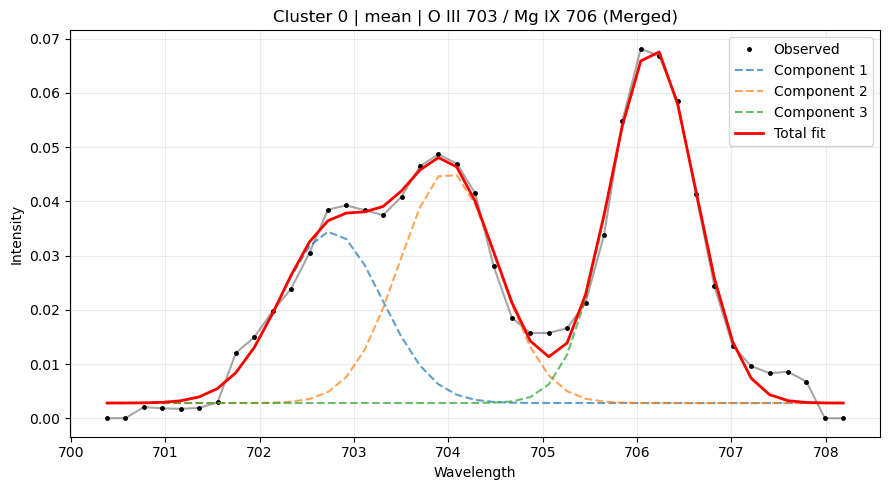

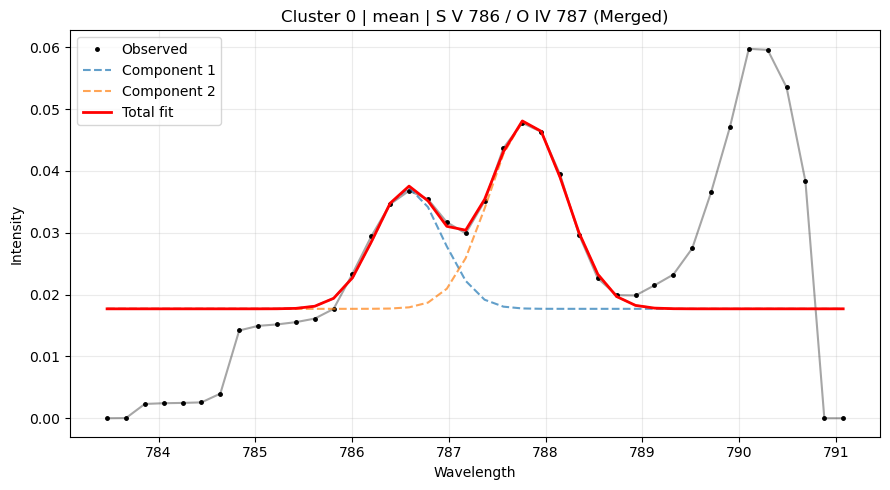

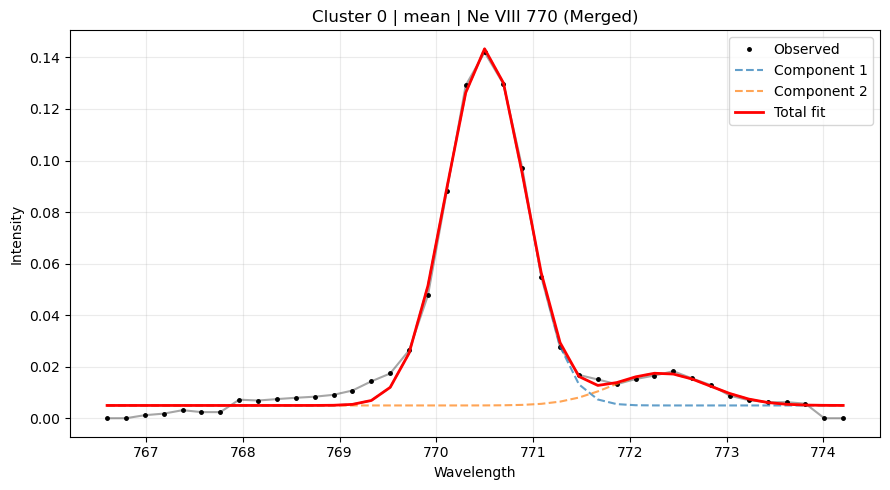

mean:  20%|██        | 1/5 [00:00<00:02,  1.69it/s]

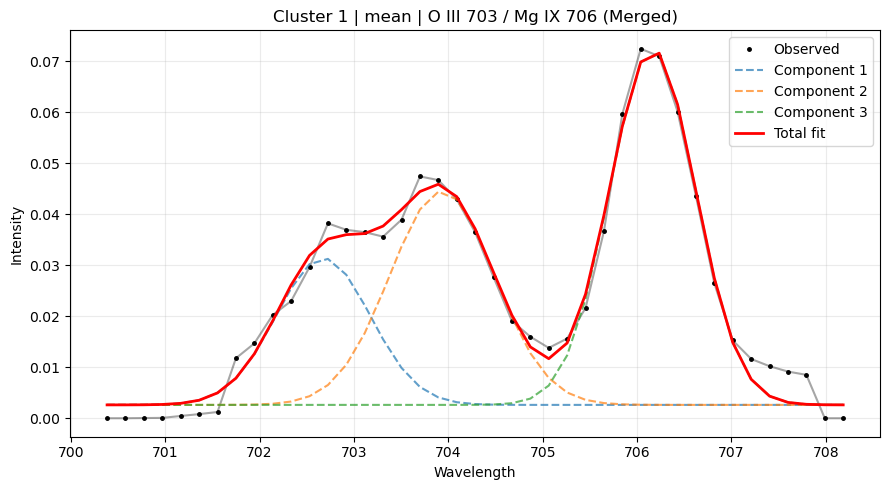

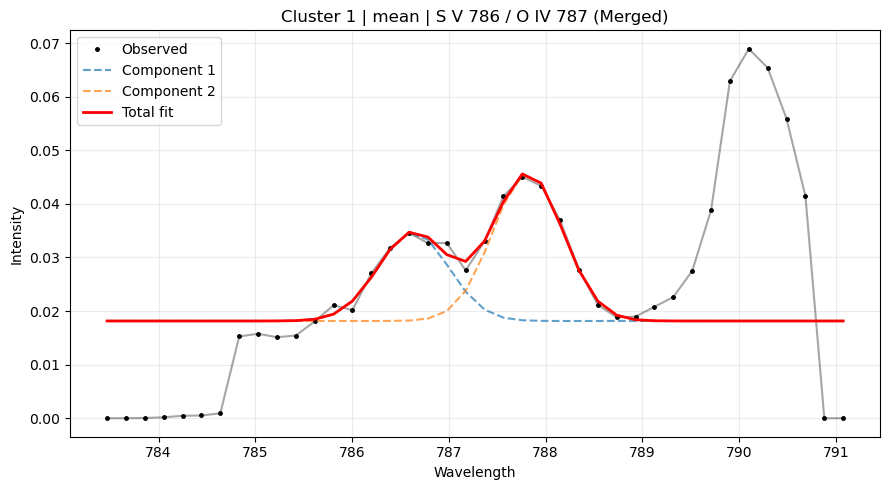

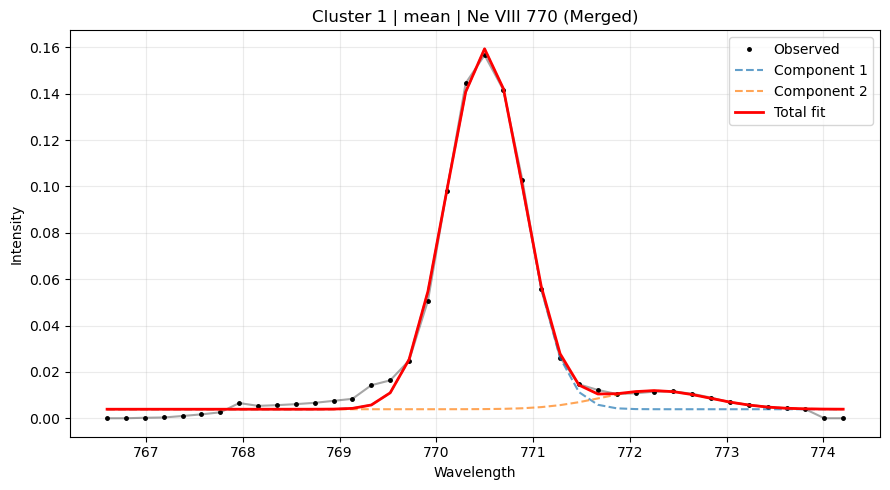

mean:  40%|████      | 2/5 [00:00<00:01,  2.08it/s]

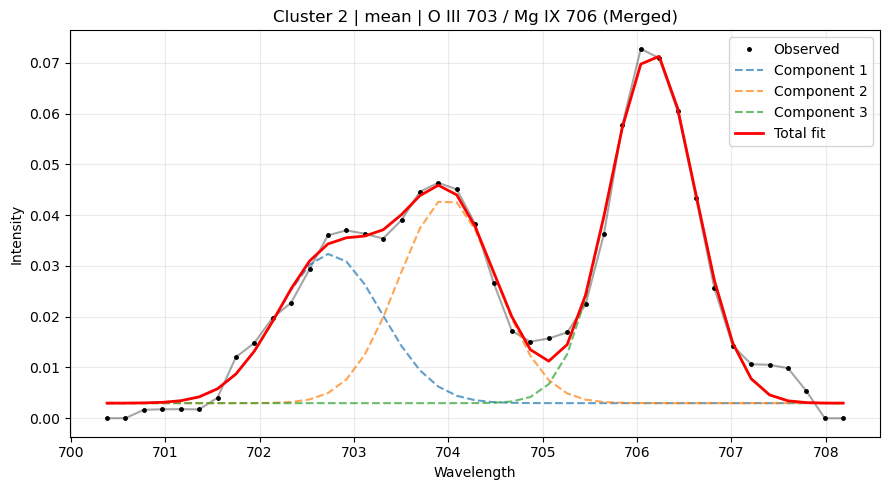

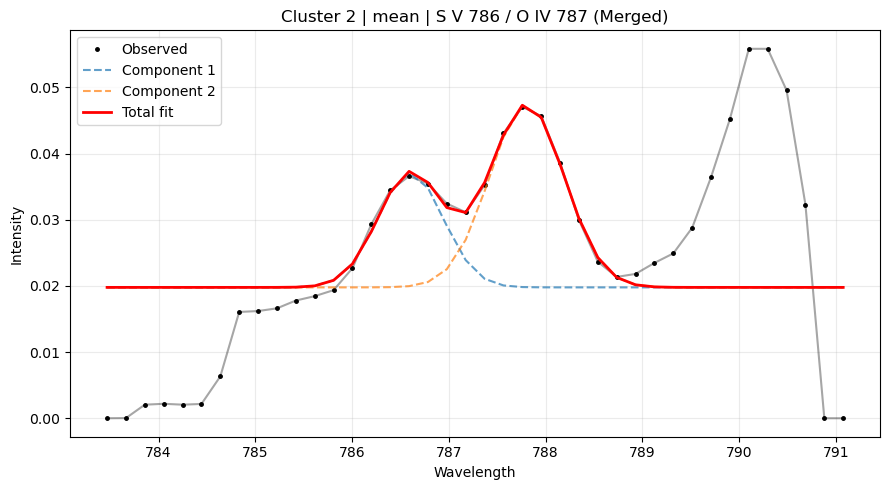

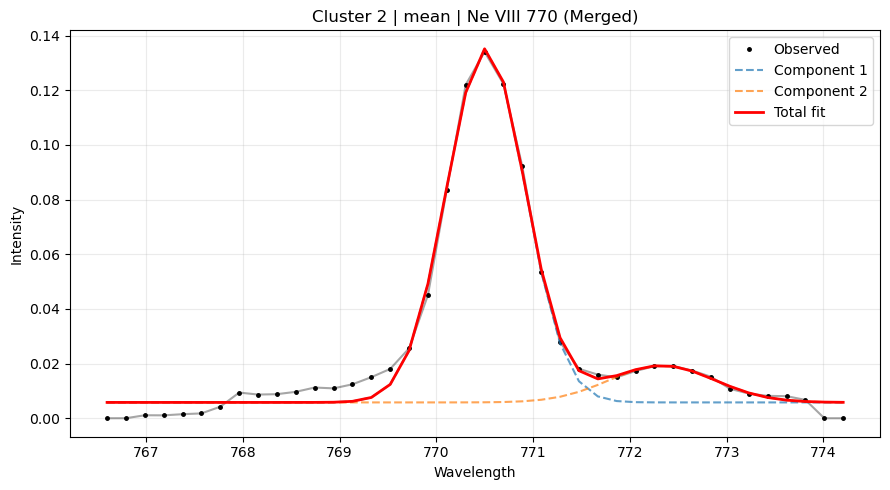

mean:  60%|██████    | 3/5 [00:01<00:00,  2.28it/s]

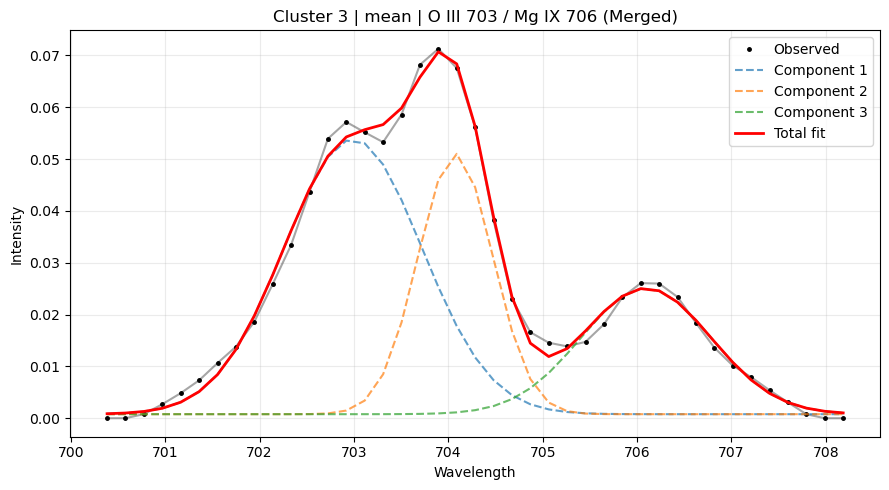

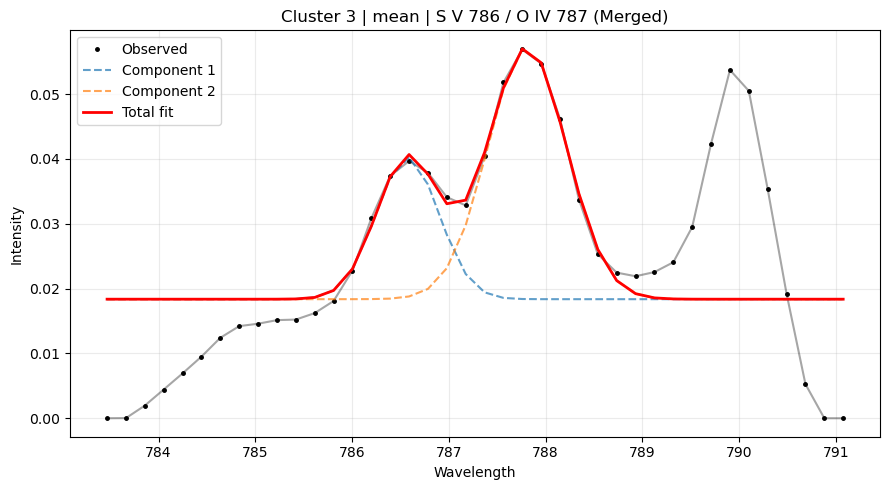

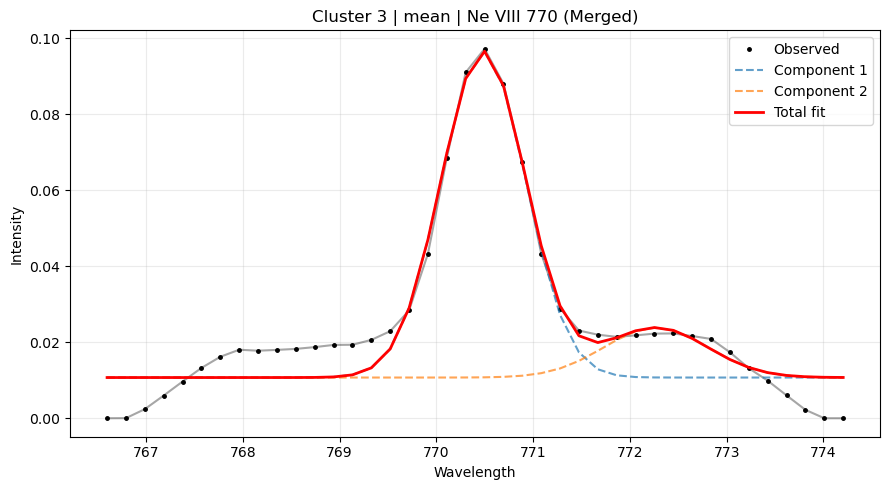

mean:  80%|████████  | 4/5 [00:01<00:00,  2.39it/s]

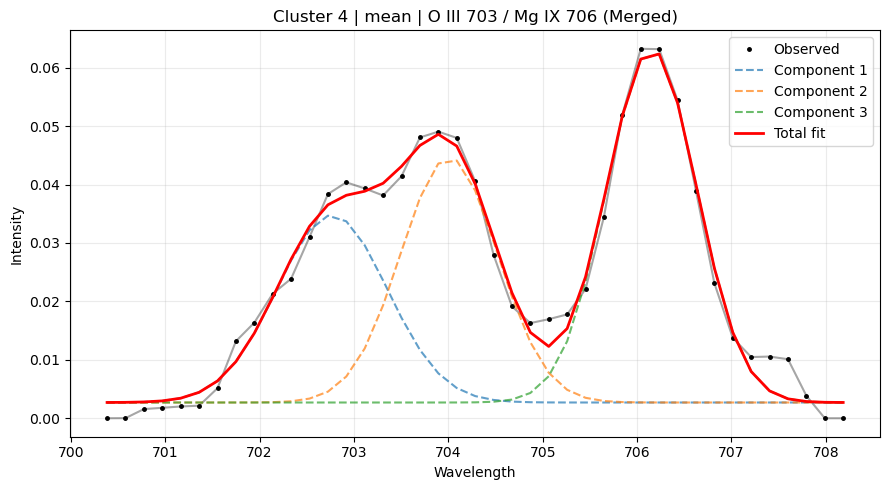

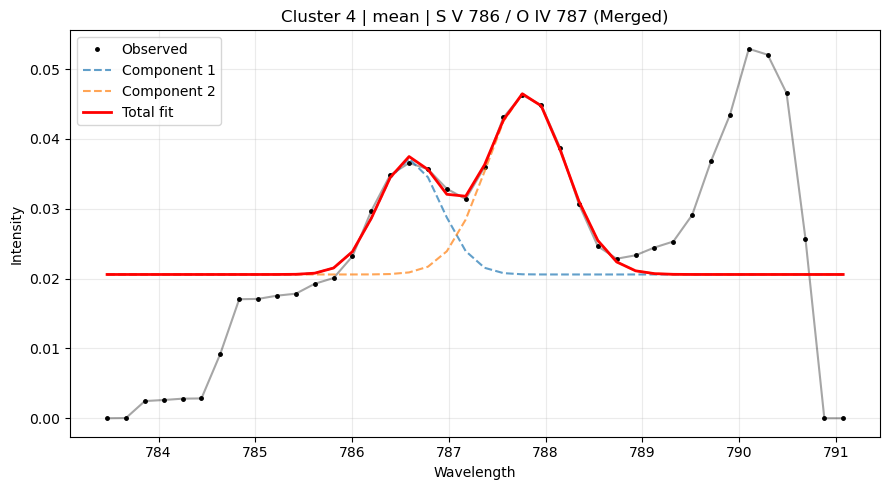

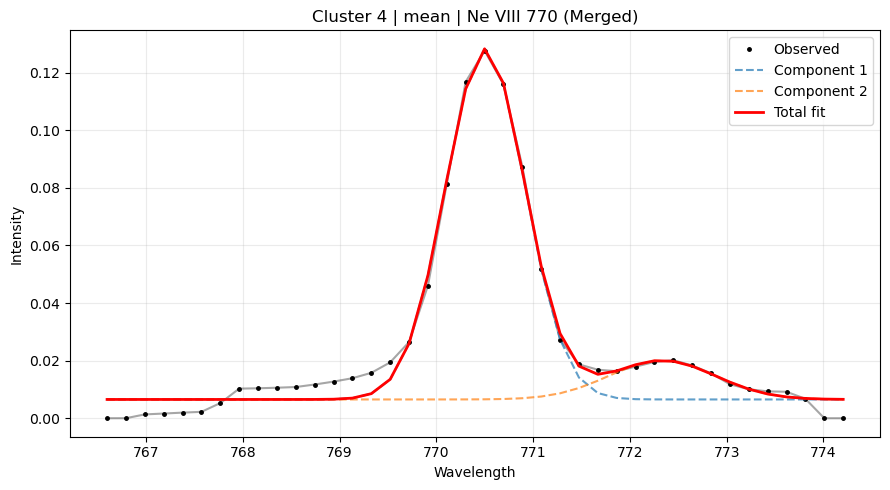

p25:   0%|          | 0/5 [00:00<?, ?it/s]

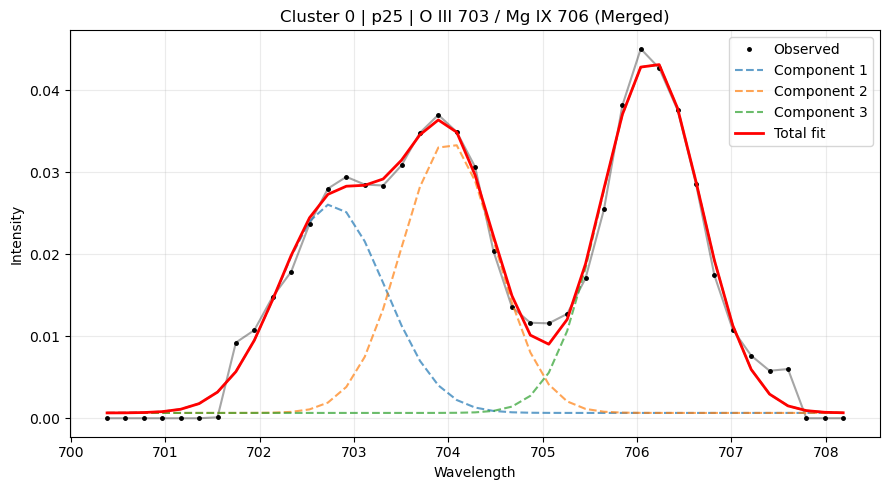

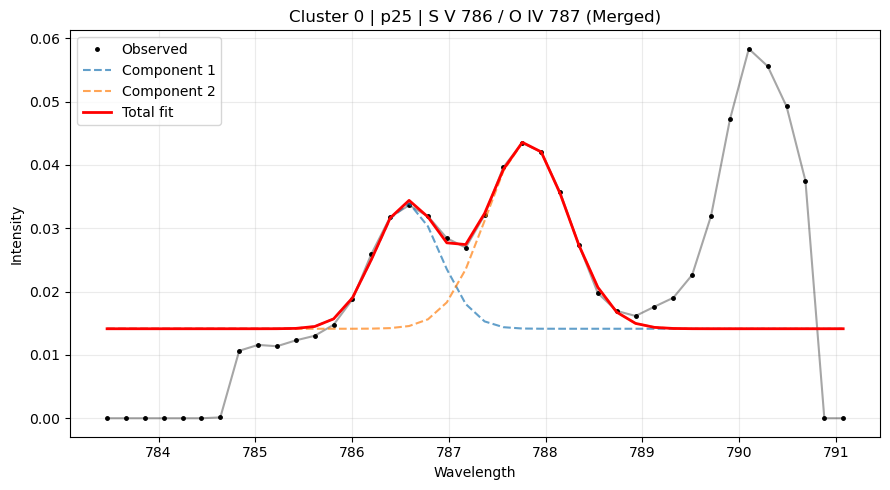

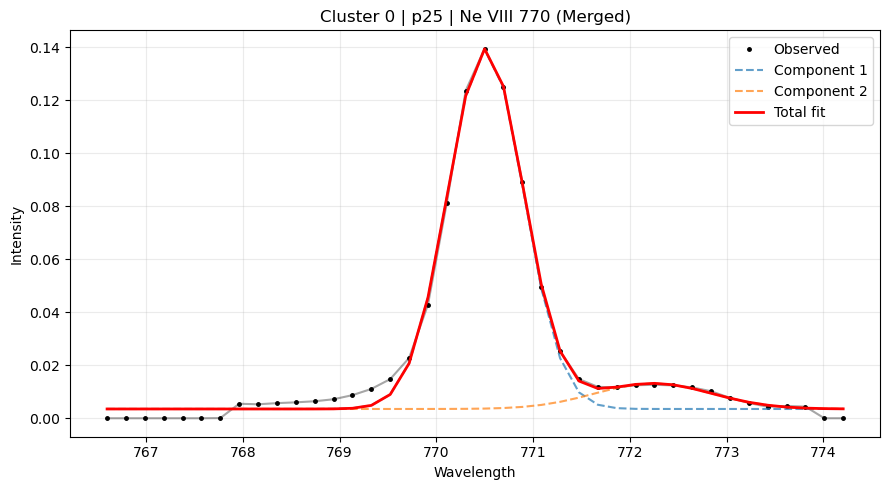

p25:  20%|██        | 1/5 [00:00<00:01,  2.64it/s]

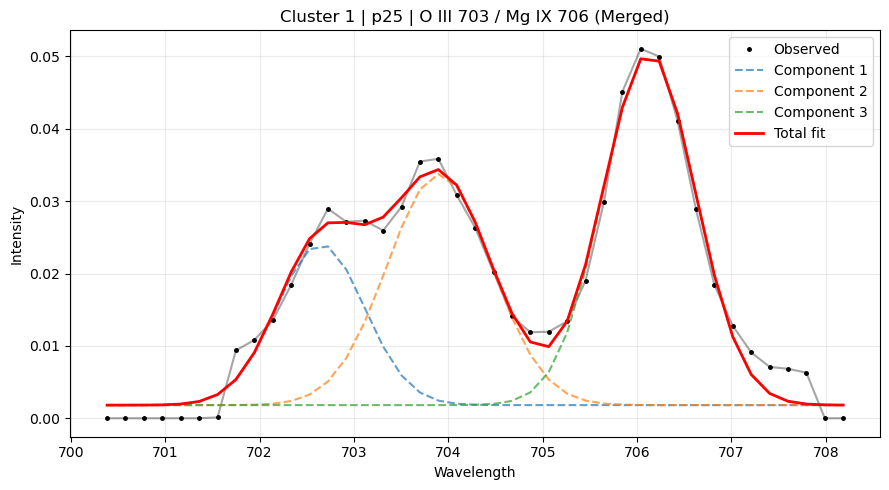

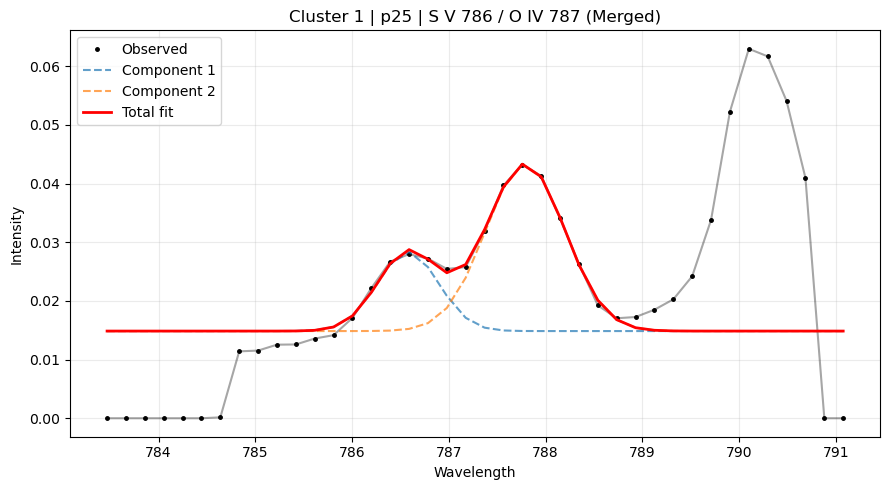

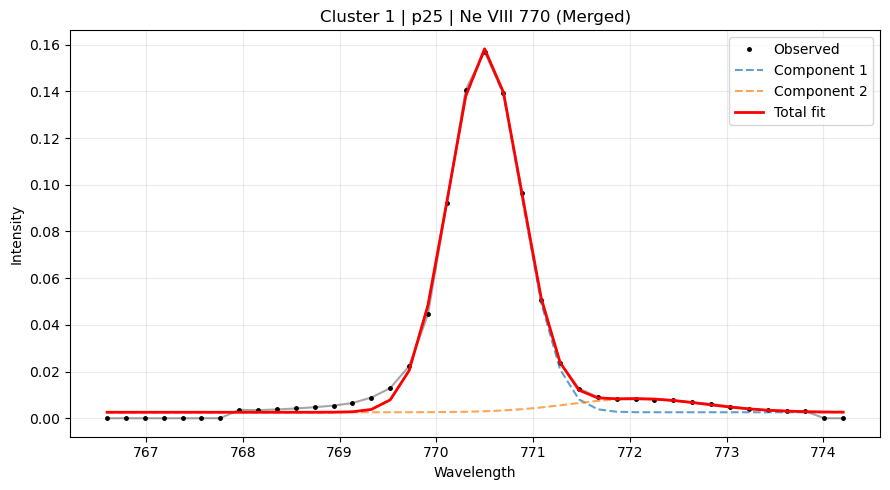

p25:  40%|████      | 2/5 [00:00<00:01,  2.60it/s]

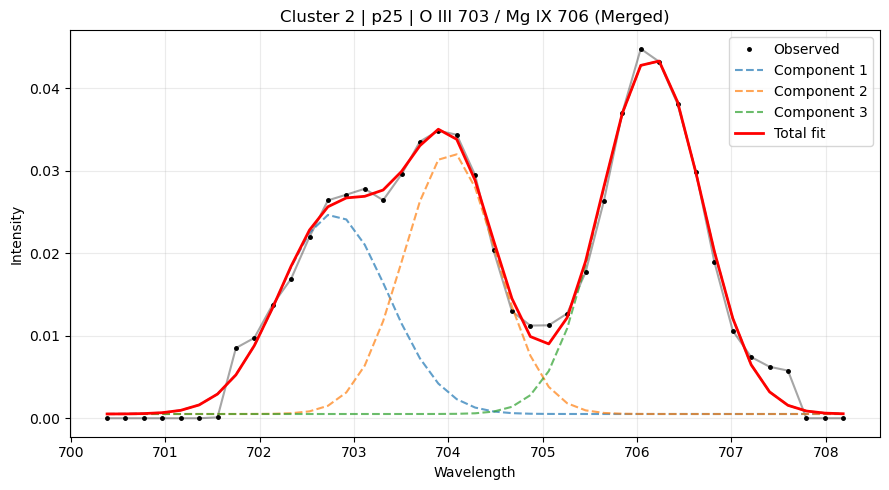

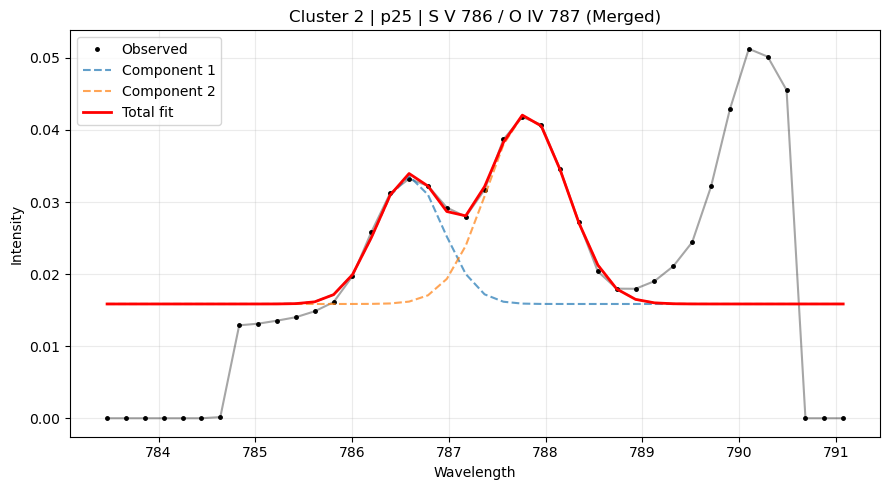

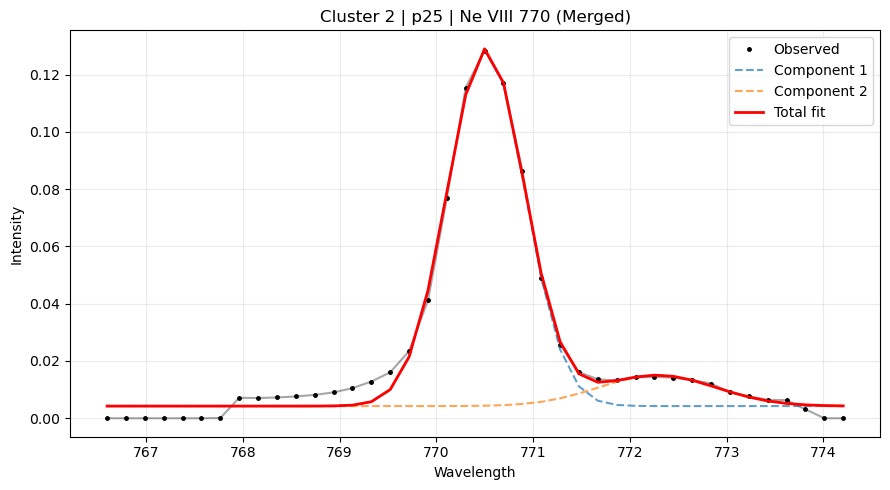

p25:  60%|██████    | 3/5 [00:01<00:00,  2.63it/s]

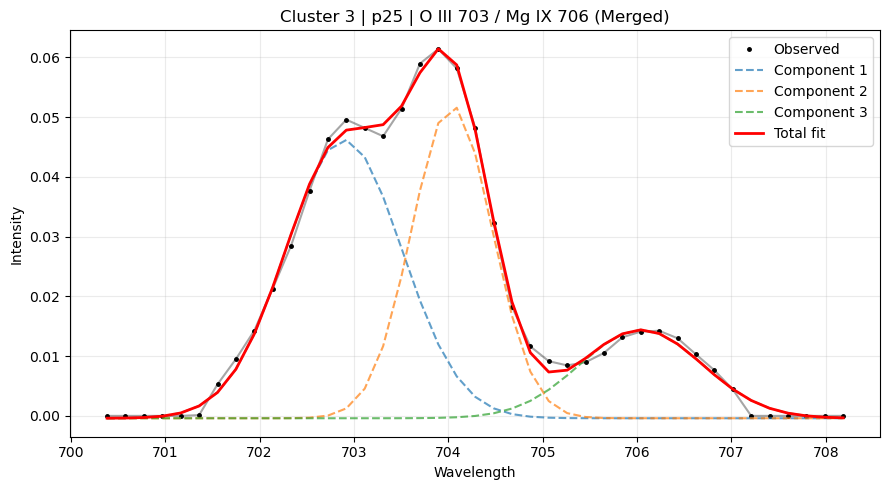

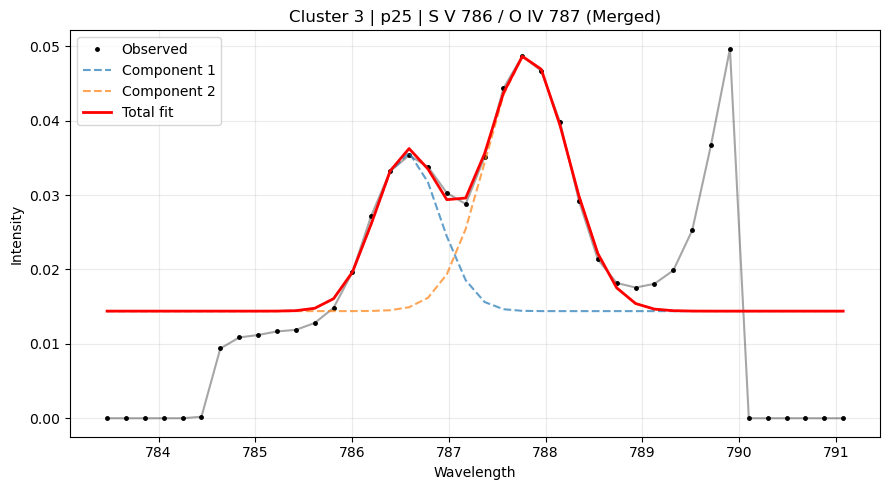

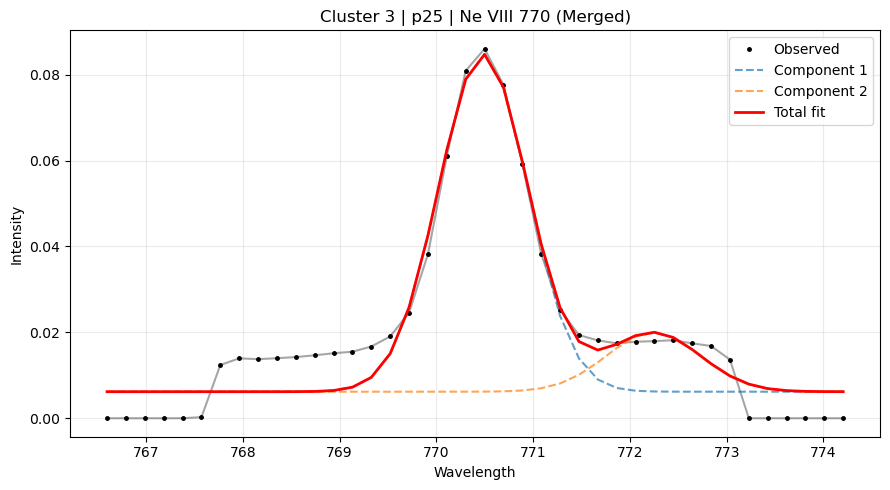

p25:  80%|████████  | 4/5 [00:01<00:00,  2.64it/s]

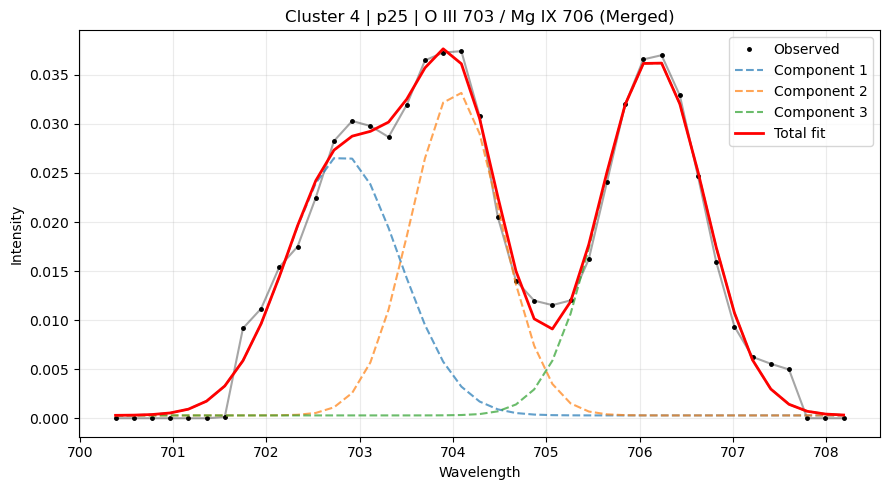

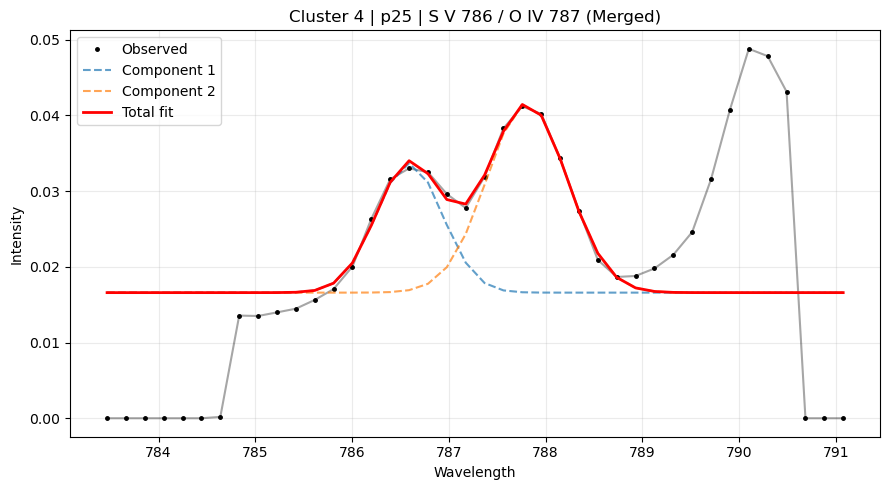

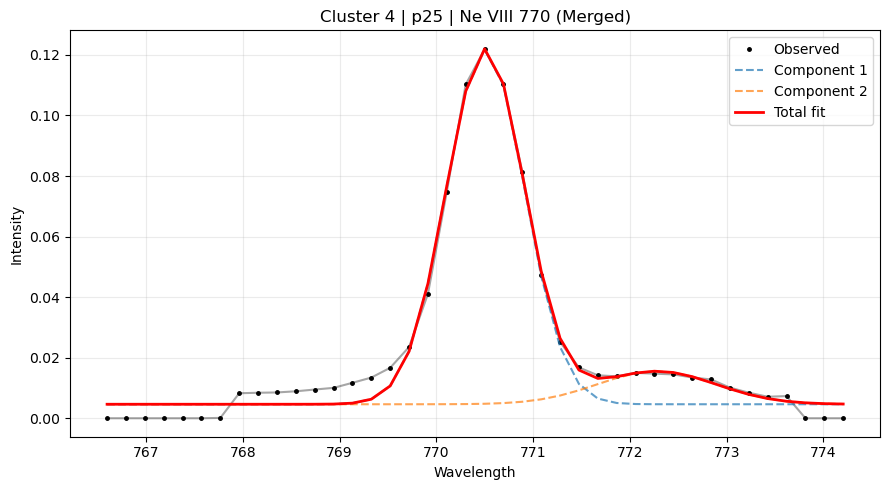

p75:   0%|          | 0/5 [00:00<?, ?it/s]

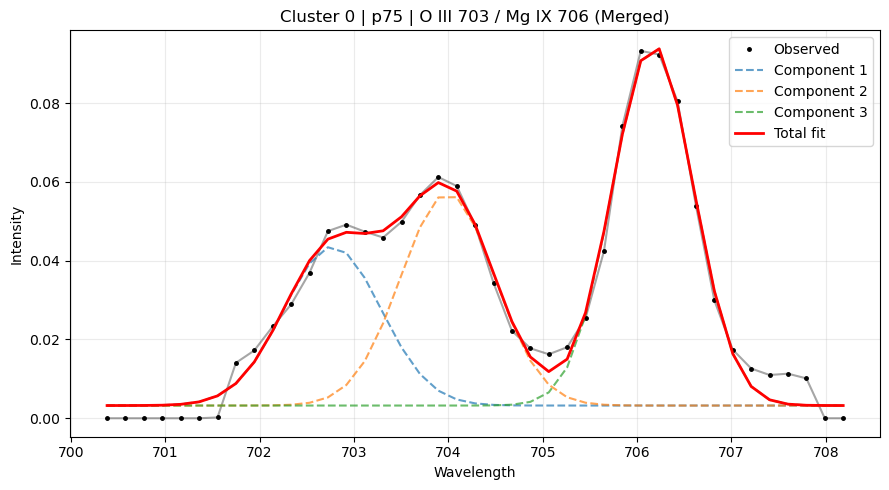

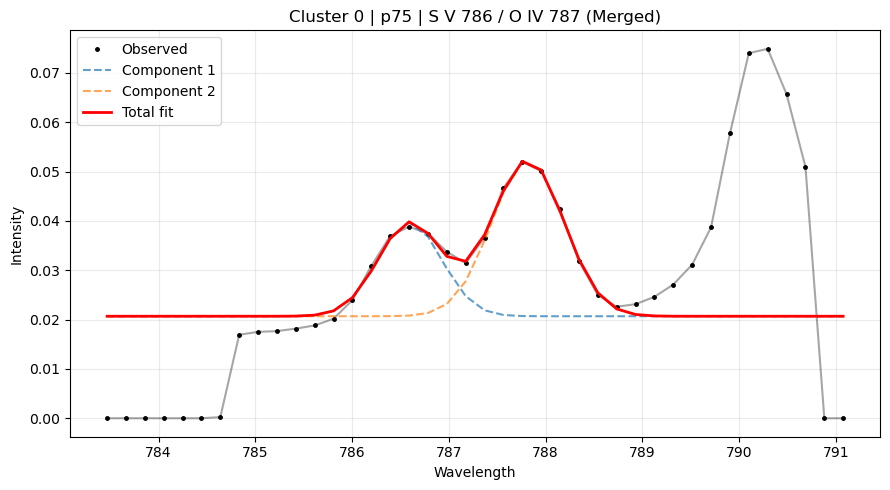

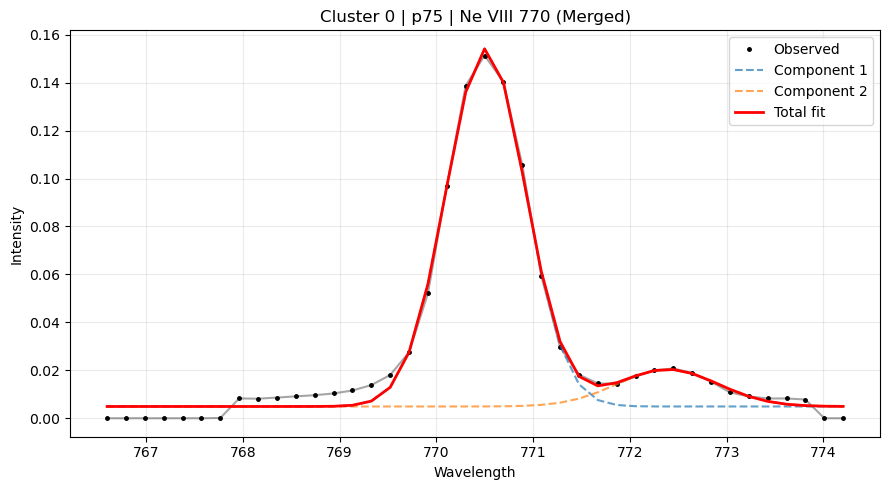

p75:  20%|██        | 1/5 [00:00<00:01,  2.59it/s]

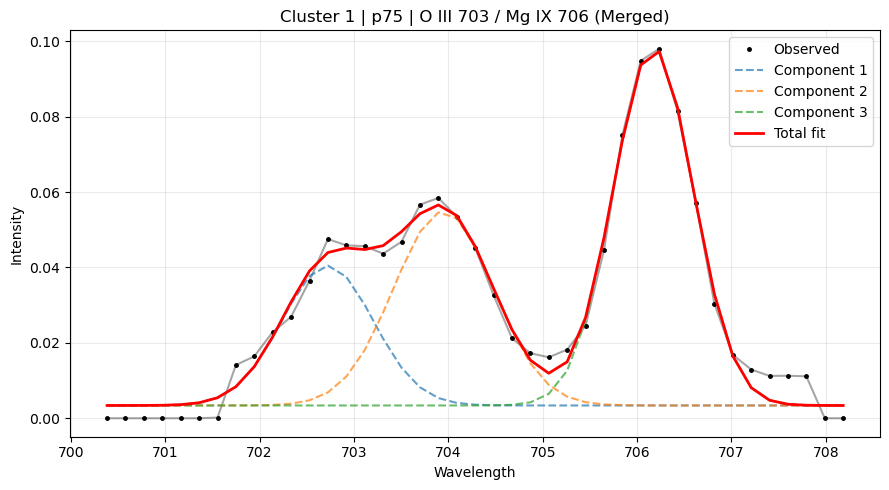

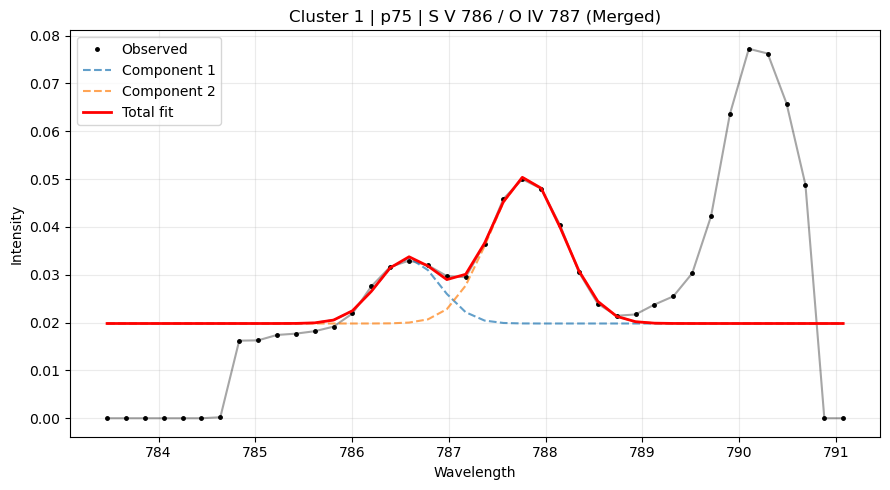

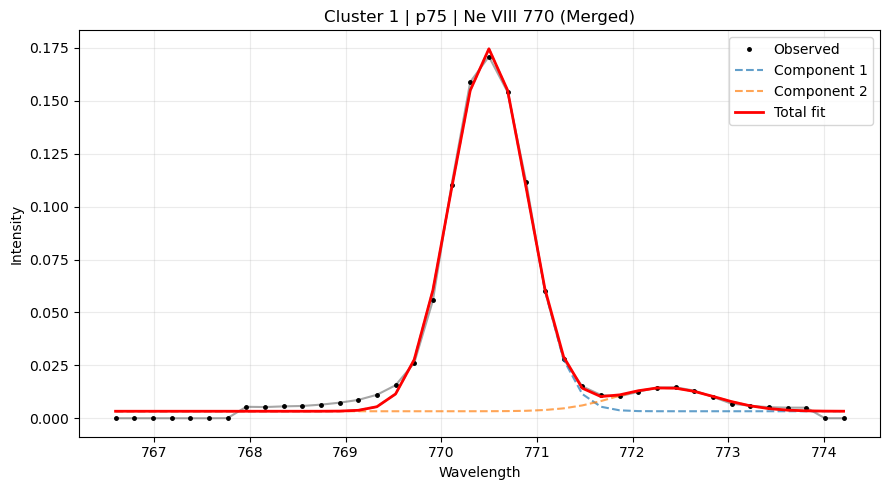

p75:  40%|████      | 2/5 [00:00<00:01,  2.58it/s]

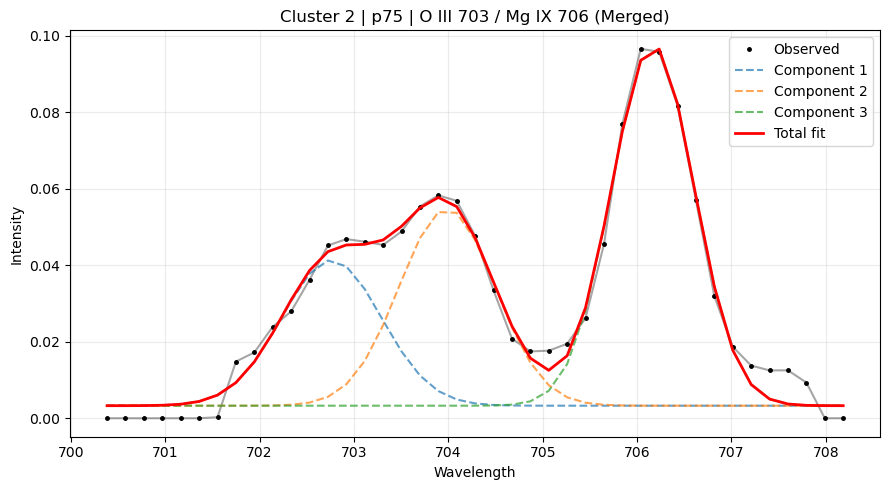

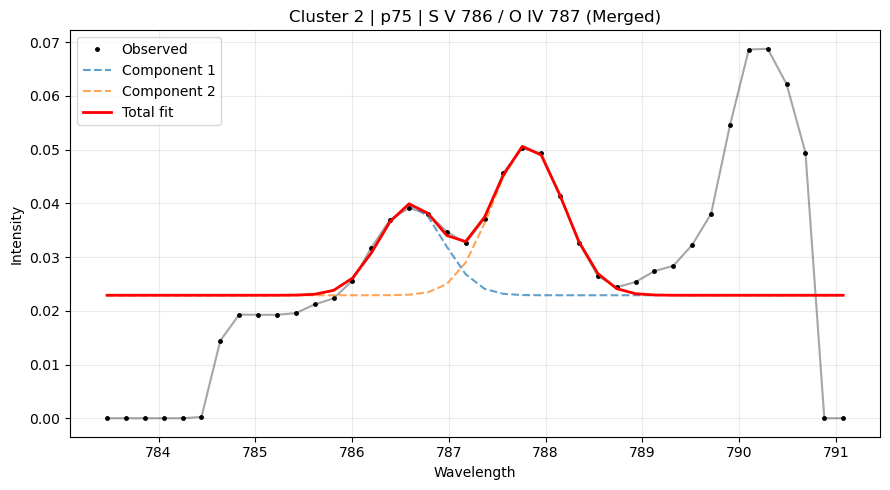

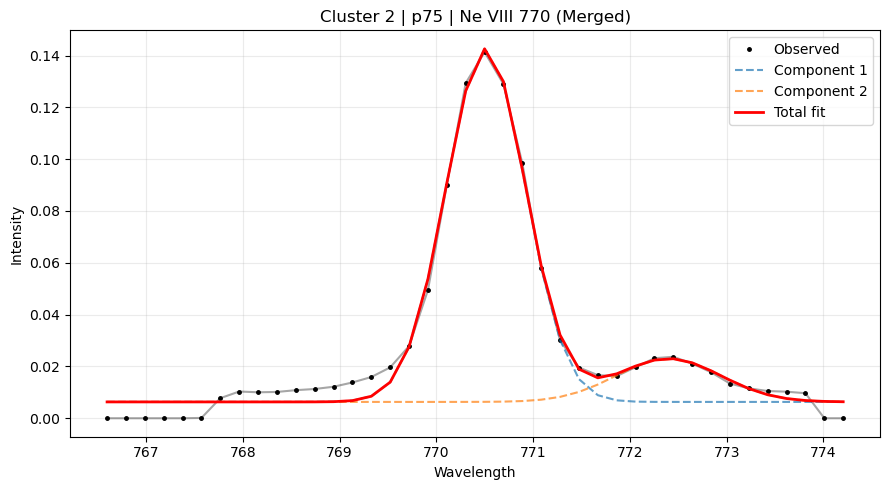

p75:  60%|██████    | 3/5 [00:01<00:00,  2.57it/s]

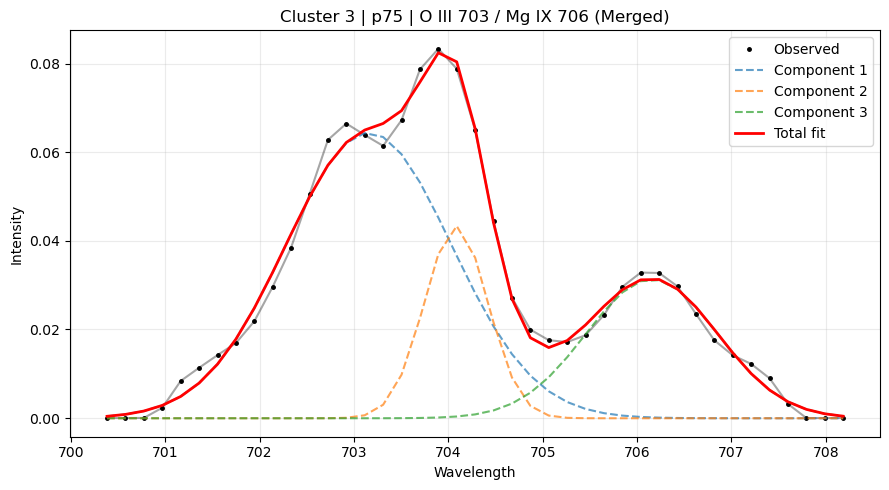

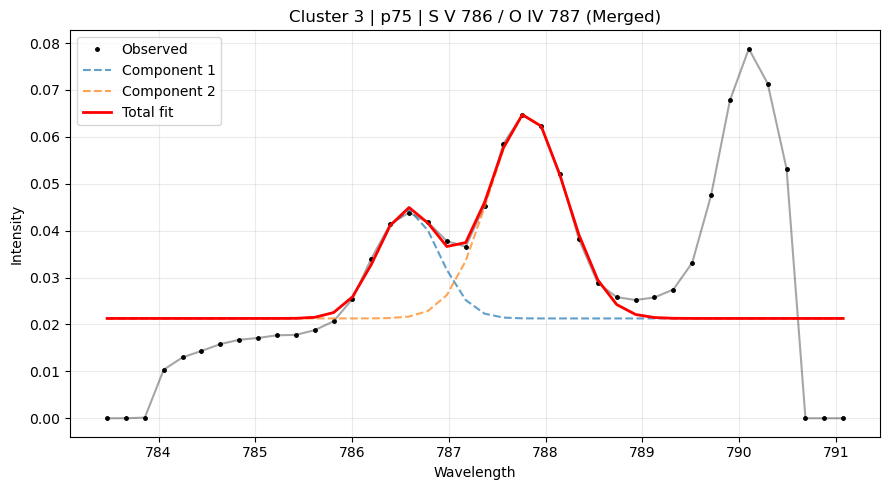

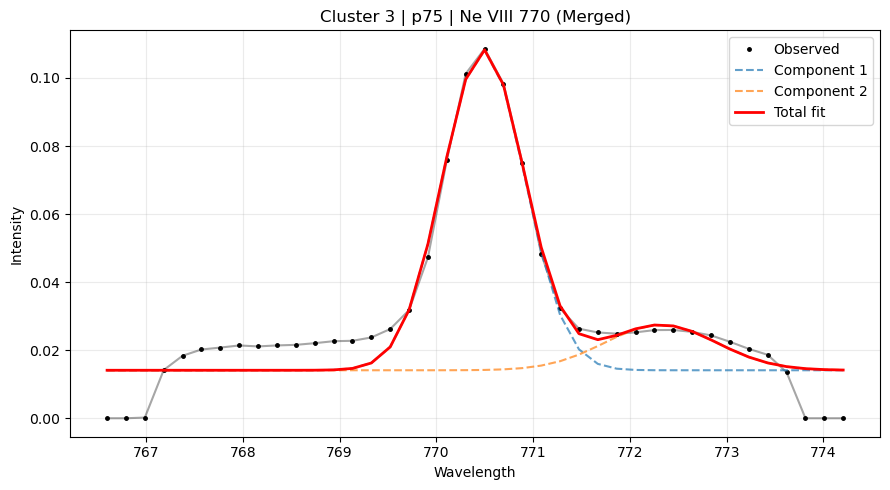

p75:  80%|████████  | 4/5 [00:01<00:00,  2.57it/s]

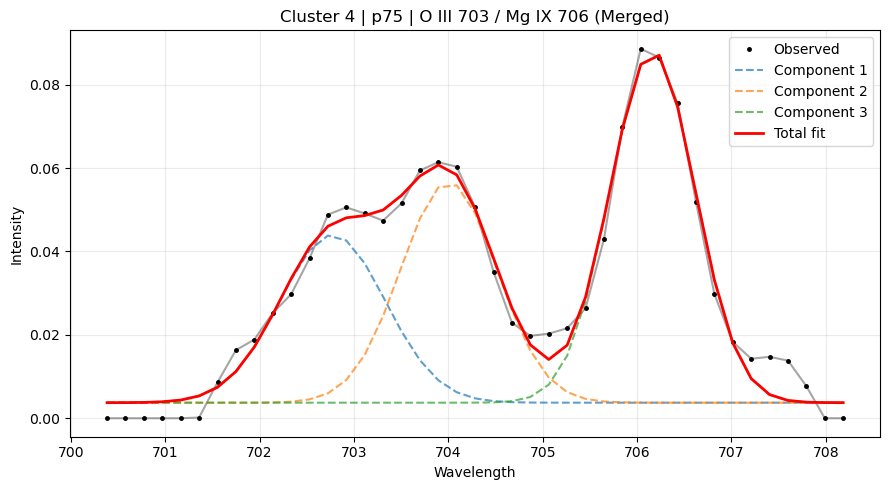

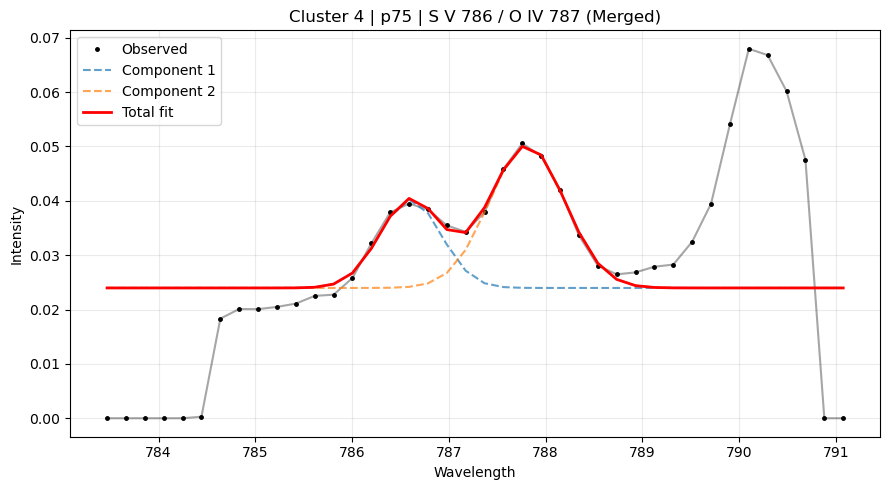

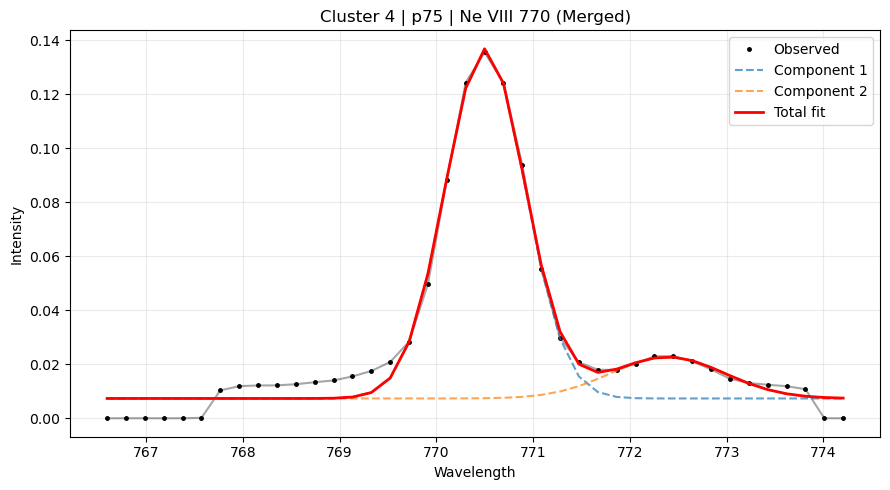

p75: 100%|██████████| 5/5 [00:01<00:00,  2.58it/s]


In [23]:
window_configs = [
    (slice(0, 41), "O III 703 / Mg IX 706 (Merged)"),
    (slice(41, 81), "S V 786 / O IV 787 (Merged)"),
    (slice(81, 121), "Ne VIII 770 (Merged)"),
]

spectra_types = {
    "mean": mean_spectra,
    "p25": p25_spectra,
    "p75": p75_spectra
}

all_results = []

for spec_type, spectra_array in spectra_types.items():

    for i, cluster_id in enumerate(tqdm(cluster_ids, desc=spec_type)):

        for sl, key in window_configs:

            try:
                results = FIP.fit_cluster_spectrum(
                    wvl=wvl[sl],
                    flux=spectra_array[i, sl],
                    config=fit_parameters[key],
                    crop=(key == "S V 786 / O IV 787 (Merged)") )

                for result in results:
                    all_results.append({
                        "cluster_id": cluster_id,
                        "spectrum_type": spec_type,
                        "line": key,
                        **result })

                plot_spectral_fit(wvl=wvl[sl], flux=spectra_array[i, sl], results=results, cluster_id=cluster_id,
                    spec_type=spec_type, line=key,)

            except Exception as e:
                print(f"Fit failed: {cluster_id}, {spec_type}, {key}: {e}")

                n_components = sum(k in fit_parameters[key] for k in ("mean", "mean1", "mean2"))

                for j in range(n_components):
                    all_results.append({
                        "cluster_id": cluster_id,
                        "spectrum_type": spec_type,
                        "line": key,
                        "component": j + 1,
                        "radiance": np.nan,
                        "mean": np.nan,
                        "std": np.nan,
                        "amplitude": np.nan,
                        "fwhm": np.nan,
                        "background": np.nan,
                        "rmse": np.nan,
                    })

results_df = pd.DataFrame(all_results)

In [20]:
mean_cluster_0 = results_df[(results_df["cluster_id"]==0) & (results_df["spectrum_type"]=='mean')]
mean_cluster_1 = results_df[(results_df["cluster_id"]==1) & (results_df["spectrum_type"]=='mean')].reset_index(drop=True)
mean_cluster_2 = results_df[(results_df["cluster_id"]==2) & (results_df["spectrum_type"]=='mean')].reset_index(drop=True)
mean_cluster_3 = results_df[(results_df["cluster_id"]==3) & (results_df["spectrum_type"]=='mean')].reset_index(drop=True)
mean_cluster_4 = results_df[(results_df["cluster_id"]==4) & (results_df["spectrum_type"]=='mean')].reset_index(drop=True)

In [21]:
mean_cluster_0

,cluster_id,spectrum_type,line,component,radiance,mean,std,amplitude,fwhm,background,rmse
0,0,mean,O III 703 / Mg IX 706 (Merged),1,0.042919,702.755892,0.540984,0.031650,1.273920,0.002807,0.002316
1,0,mean,O III 703 / Mg IX 706 (Merged),2,0.055262,703.998872,0.516546,0.042680,1.216372,0.002807,0.002316
2,0,mean,O III 703 / Mg IX 706 (Merged),3,0.074409,706.164152,0.453007,0.065528,1.066750,0.002807,0.002316
3,0,mean,S V 786 / O IV 787 (Merged),1,0.017093,786.577622,0.347700,0.019613,0.818770,0.017696,0.001266
4,0,mean,S V 786 / O IV 787 (Merged),2,0.030215,787.812489,0.393797,0.030609,0.927322,0.017696,0.001266
5,0,mean,Ne VIII 770 (Merged),1,0.140398,770.510743,0.404580,0.138441,0.952714,0.004965,0.002972
6,0,mean,Ne VIII 770 (Merged),2,0.015900,772.319703,0.503739,0.012592,1.186215,0.004965,0.002972


## FIP calculation (2LR)

### Mean spectra

In [7]:
FIP_2LR_mean = {"MgNe": {}, "SO": {}}

for cluster_id in cluster_ids:

    cluster = results_df[(results_df["cluster_id"] == cluster_id) & (results_df["spectrum_type"] == "mean")].reset_index(drop=True)
    FIP_2LR_mean['MgNe'][cluster_id], _ = FIP._2LR_FIP(cluster.at[2, "radiance"], cluster.at[5, "radiance"], "Mg IX 706", "Ne VIII 770.4")
    FIP_2LR_mean['SO'][cluster_id], _ = FIP._2LR_FIP(cluster.at[3, "radiance"], cluster.at[4, "radiance"], "S V 786.4", "O IV 787.7")

In [8]:
FIP_2LR_mean['SO'][4]

np.float64(1.0083793062528332)

### p25

In [9]:
FIP_2LR_p25 = {"MgNe": {}, "SO": {}}

for cluster_id in cluster_ids:

    cluster = results_df[(results_df["cluster_id"] == cluster_id) & (results_df["spectrum_type"] == "p25")].reset_index(drop=True)
    FIP_2LR_p25['MgNe'][cluster_id], _ = FIP._2LR_FIP(cluster.at[2, "radiance"], cluster.at[5, "radiance"], "Mg IX 706", "Ne VIII 770.4")
    FIP_2LR_p25['SO'][cluster_id], _ = FIP._2LR_FIP(cluster.at[3, "radiance"], cluster.at[4, "radiance"], "S V 786.4", "O IV 787.7")

### p75

In [10]:
FIP_2LR_p75 = {"MgNe": {}, "SO": {}}

for cluster_id in cluster_ids:

    cluster = results_df[(results_df["cluster_id"] == cluster_id) & (results_df["spectrum_type"] == "p75")].reset_index(drop=True)
    FIP_2LR_p75['MgNe'][cluster_id], _ = FIP._2LR_FIP(cluster.at[2, "radiance"], cluster.at[5, "radiance"], "Mg IX 706", "Ne VIII 770.4")
    FIP_2LR_p75['SO'][cluster_id], _ = FIP._2LR_FIP(cluster.at[3, "radiance"], cluster.at[4, "radiance"], "S V 786.4", "O IV 787.7")

## DEM method

In [11]:
import simspice.emtoolkit.emtoolkit.EMToolKit as emtk

from simspice.emtoolkit.emtoolkit.algorithms.simple_reg_dem_wrapper import (simple_reg_dem_wrapper)
from simspice.emtoolkit.emtoolkit.algorithms.sparse_nlmap_dem_wrapper import (sparse_nlmap_dem_wrapper)

In [12]:
selected_lines = {"O III 702.8": ("O III 703 / Mg IX 706 (Merged)", 1),
    "O III 703.8": ("O III 703 / Mg IX 706 (Merged)", 2),
    "Mg IX 706.0": ("O III 703 / Mg IX 706 (Merged)", 3),
    "Ne VIII 770.4": ("Ne VIII 770 (Merged)", 1),
    "Mg VIII 772.3": ("Ne VIII 770 (Merged)", 2 ),
    "S V 786.4": ("S V 786 / O IV 787 (Merged)", 1),
    "O IV 787.7": ("S V 786 / O IV 787 (Merged)", 2),}

In [13]:
import astropy.units as u
from astropy.nddata import StdDevUncertainty
from sunpy.map import Map
from astropy.wcs import WCS
import sunpy
from astropy.io.fits import Header
import sunpy.map
from astropy.time import Time

def make_frame_map(lat=None, lon=None, rad=None, tim=None, 
			nx=None, ny=None, dx=None, dy=None, rota=0.0,
			xrefpx=None, yrefpx=None, xrefcrd=None, yrefcrd=None, dat=None):
		
	from sunpy.coordinates import frames
	from astropy.coordinates import SkyCoord

	if('unit' not in dir(lat) and lat is not None): lat=lat*u.deg
	if('unit' not in dir(lon) and lon is not None): lon=lon*u.deg
	if('unit' not in dir(rad) and rad is not None): rad=rad*u.m
	if('unit' in dir(dx)):
		scale = np.array([dx.value,dy.value])*dx.unit
	else:
		scale = np.array([dx,dy])*u.arcsec/u.pix
	if('unit' in dir(xrefpx)):
		refpx = np.array([xrefpx.value, yrefpx.value])*xrefpx.unit
	else:
		refpx = np.array([xrefpx,yrefpx])*u.pix
	if('unit' not in dir(xrefcrd)): xrefcrd = xrefcrd*u.arcsec
	if('unit' not in dir(yrefcrd)): yrefcrd = yrefcrd*u.arcsec
	if('unit' not in dir(rota)): rota = rota*u.deg
	
	if(dat is None): dat = np.zeros([nx,ny])
	if(lat is not None or lon is not None or rad is not None):
		obscoord = SkyCoord(frame=frames.HeliographicStonyhurst, lon=lon, lat=lat, 
							radius=rad, obstime=tim)
	else:
		obscoord = 'earth'
	srccoord = SkyCoord(xrefcrd,yrefcrd, obstime=tim, observer=obscoord,
						frame=frames.Helioprojective)

	header = sunpy.map.make_fitswcs_header(dat.T, srccoord, scale=scale,
											reference_pixel=refpx, rotation_angle=rota)
	frame_map = sunpy.map.Map(dat.T, header)
	return frame_map, header

def spice_wrapper_varesano(windat, names, logts, trsps, wcs=None, date_obs=None, err_fac=1, spice_header=None):
	
	data_names = windat['lines']
	output_maps, output_errs, output_logts, output_trsps = [[],[],[],[]]
	for i in range(0,len(data_names)):
		# print(data_names[i],np.array(names))
		check = data_names[i]==np.array(names)
		if(np.sum(check)):
			data = np.asarray(windat['rad'][i])

			if wcs is not None:
				# If the input is a SunPy map, use its WCS
				if isinstance(wcs, sunpy.map.GenericMap):
					wcs = wcs.wcs

				# If the input is a FITS header, convert to WCS
				elif isinstance(wcs, (Header, dict)):
					wcs = WCS(wcs)

				# Check input
				if not isinstance(wcs, WCS):
					raise TypeError(f"Expected WCS, SunPy Map or FITS header, got {type(wcs)}"	)

				# Extract 2D spatial WCS from 4D SPICE WCS
				spatial_wcs = extract_spatial_wcs(wcs)
				header = spatial_wcs.to_header()
				if spice_header is not None:
					for keyword in ["HGLN_OBS", "HGLT_OBS", "DSUN_OBS",	"CRLN_OBS", "CRLT_OBS", "RSUN_REF"]:
						if keyword in spice_header:
							header[keyword] = spice_header[keyword]

				if date_obs is not None:
					header["DATE-OBS"] = Time(date_obs).isot

				smap = Map(data, header)

			else:
				smap, hdr = make_frame_map(tim = '2022-12-20T00:00:00',dat=windat['rad'][i], rad=1.49e13, lon=0.0, lat=0.0,
												   dx=1.0,dy=1.0,rota=0.0, xrefpx=0,yrefpx=0,xrefcrd=0,	yrefcrd=0)
			smap.meta['detector'] = 'SPICE_FIT '
			smap.meta['exptime'] = 1
			smap.meta['wave_str'] = data_names[i]
			output_maps.append(smap)
			output_errs.append(StdDevUncertainty(np.abs(smap.data) / err_fac))
			# In case errors not reliable: 
			# This is a crude uncertainty estimate based on the line amplitude:
			# output_errs.append(StdDevUncertainty(np.clip(5*windat['rad'][i],2.5,None)**0.5))
			#print(err[i].shape)
			output_trsps.append(trsps[check])
			output_logts.append(logts.to_value(u.K))
			# plt.figure(figsize=(14,5))
			# plt.subplot(1,2,1)
			# plt.plot(np.log10(logts), trsps[check].flatten()), plt.title(data_names[i]) #,plt.yscale('log')
			# plt.subplot(1,2,2)
			# plt.imshow(map.data**.5, aspect=1/2, vmax=30)
			# plt.show()
	return output_maps,output_errs,output_logts,output_trsps

def computing_DEM_cluster(
    results_df,
    cluster_id,
    spectrum_type,
    selected_lines,
    contribution_dict,
    logts,
    error_fraction=0.15
):
    # Prepare contribution functions
    names = [
        ion + " " + str(wvl)
        for ion, wvl in contribution_dict.keys()
    ]

    trsps = np.array([
        np.asarray(g.value).squeeze()
        for g in contribution_dict.values()
    ])

    # Select cluster and spectrum type
    cluster = results_df[
        (results_df["cluster_id"] == cluster_id) &
        (results_df["spectrum_type"] == spectrum_type)
    ]

    windat = {"lines": [], "rad": [], "err": []}

    for ion, (window, component) in selected_lines.items():

        # Check whether this ion exists in contribution functions
        if ion not in names:
            print(f"Skipping {ion}: no contribution function")
            continue

        # Find fitted radiance
        fit = cluster[
            (cluster["line"] == window) &
            (cluster["component"] == component)
        ]

        if len(fit) != 1:
            print(f"Skipping {ion}: missing or duplicate fit")
            continue

        rad = float(fit["radiance"].iloc[0])

        # DEM requires positive finite radiances
        if not np.isfinite(rad) or rad <= 0:
            continue

        # Assume 15% uncertainty
        err = error_fraction * abs(rad)

        windat["lines"].append(ion)
        windat["rad"].append(np.array([[rad]]))
        windat["err"].append(np.array([[err]]))

    if len(windat["lines"]) < 2:
        raise ValueError(
            f"Insufficient lines for cluster {cluster_id}, "
            f"{spectrum_type}"
        )

    # Create 1x1 SunPy maps
    # Existing wrapper calculates sigma = |radiance| / err_fac
    maps, uncertainties, temperatures, responses = spice_wrapper_varesano(
        windat,
        names,
        logts,
        trsps,
        err_fac=1 / error_fraction
    )

    if len(maps) != len(windat["lines"]):
        raise ValueError("Some spectral lines were not matched.")

    # Prepare EMToolKit input
    datasequence = emtk.em_data(
        maps,
        uncertainties,
        temperatures,
        responses
    )

    # DEM inversion
    result = simple_reg_dem_wrapper(datasequence)

    coeffs, logts_out, bases, coords = result[:4]
    chi2 = result[5]

    coefficients = np.asarray(coeffs)[:, 0, 0]

    return {
        "coefficients": coefficients,
        "logts": logts_out,
        "bases": bases,
        "chi2": chi2,
        "lines": windat["lines"],
        "radiances": np.array([
            r[0, 0] for r in windat["rad"]
        ]),
        "errors": np.array([
            e[0, 0] for e in windat["err"]
        ]),
        "result": result
    }

In [14]:
from tqdm.auto import tqdm
import pickle 

with open('/d0/tvaresano/SimSPICE/simspice/utils/contribution_dict_fiasco_v11_blended_coro_schmelz_100pt.pkl', 'rb') as f:
    dict_coro = pickle.load(f)

logts = np.geomspace(5e4, 5e6, 100) * u.K
dem_results = {"mean": {}, "p25": {}, "p75": {}}

for spectrum_type in ["mean", "p25", "p75"]:

    for cluster_id in tqdm(cluster_ids, desc=f"DEM {spectrum_type}" ):

        try:
            dem_results[spectrum_type][int(cluster_id)] = computing_DEM_cluster(
                results_df=results_df,
                cluster_id=cluster_id,
                spectrum_type=spectrum_type,
                selected_lines=selected_lines,
                contribution_dict=dict_coro,
                logts=logts,
                error_fraction=0.15 )

        except Exception as e:
            print(f"DEM failed for cluster {cluster_id}, "  f"{spectrum_type}: {e}")

DEM mean:  20%|██        | 1/5 [00:00<00:00,  9.39it/s]

DEM p75: 100%|██████████| 5/5 [00:00<00:00,  9.94it/s]


In [15]:
FIP_DEM_mean = {}
FIP_DEM_p25 = {}
FIP_DEM_p75 = {}

fip_dicts = {"mean": FIP_DEM_mean, "p25": FIP_DEM_p25, "p75": FIP_DEM_p75}

line_pairs = {"MgNe": ("Mg IX 706.0", "Ne VIII 770.4"), "SO": ("S V 786.4", "O IV 787.7")}

for spectrum_type, fip_dict in fip_dicts.items():

    for cluster_id, dem in dem_results[spectrum_type].items():

        fip_dict[cluster_id] = {}

        # Radiances used for the DEM inversion
        radiances = dict(zip(dem["lines"], dem["radiances"]))

        # Reconstruct temperature-integrated DEM weights
        arDEM = dem_results[spectrum_type][int(cluster_id)]['coefficients']

        for ratio, (ion_low, ion_high) in line_pairs.items():

            try:
                rad_low = radiances[ion_low]
                rad_high = radiances[ion_high]

                fip_dict[cluster_id][ratio] = FIP._DEM_FIP_pxbypx(rad_low, rad_high, ion_low, ion_high, # arDEM, 
                                                                  dict_contribution=FIP.dict_contribution_func, method='chianti', abundances=FIP.abundances_p )

            except (KeyError, ValueError) as e:
                print(f"Failed: {cluster_id}, {spectrum_type}, {ratio}: {e}")
                fip_dict[cluster_id][ratio] = np.nan

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_cluster_fip(fip_mean, fip_p25, fip_p75, method="DEM"):

    def to_dataframe(fip_dict):
        # Support both dictionary structures:
        # {cluster_id: {"MgNe": ..., "SO": ...}}
        # {"MgNe": {cluster_id: ...}, "SO": {cluster_id: ...}}
        if "MgNe" in fip_dict and "SO" in fip_dict:
            df = pd.DataFrame(fip_dict)
        else:
            df = pd.DataFrame.from_dict(fip_dict, orient="index")

        df = df.sort_index()[["MgNe", "SO"]]

        # Convert scalar or 1x1 array outputs to floats
        for col in df.columns:
            df[col] = df[col].map(
                lambda v: float(np.asarray(v).item())
                if np.asarray(v).size == 1 else np.nan
            )

        return df

    # Convert dictionaries to DataFrames
    df_mean = to_dataframe(fip_mean)
    df_p25 = to_dataframe(fip_p25).reindex(df_mean.index)
    df_p75 = to_dataframe(fip_p75).reindex(df_mean.index)

    clusters = df_mean.index
    x = np.arange(len(clusters))
    width = 0.35

    fig, ax = plt.subplots(figsize=(11, 5))

    for i, ratio in enumerate(["MgNe", "SO"]):

        means = df_mean[ratio].to_numpy(dtype=float)
        p25 = df_p25[ratio].to_numpy(dtype=float)
        p75 = df_p75[ratio].to_numpy(dtype=float)

        positions = x + (i - 0.5) * width

        bars = ax.bar(
            positions,
            means,
            width=width,
            alpha=0.8,
            label=ratio
        )

        # Show p25-p75 range without assuming
        # that the mean lies between them
        ax.vlines(
            positions,
            np.minimum(p25, p75),
            np.maximum(p25, p75),
            color="black",
            linewidth=1.5
        )

        ax.plot(positions, p25, "k_", markersize=9)
        ax.plot(positions, p75, "k_", markersize=9)

    ax.axhline(1, color="gray", linestyle="--", alpha=0.7)

    ax.set_xticks(x)
    ax.set_xticklabels(clusters)
    ax.set_xlabel("Cluster ID")
    ax.set_ylabel("FIP bias")
    ax.set_title(f"FIP bias by cluster - {method} method")
    ax.legend()
    ax.grid(axis="y", alpha=0.2)

    plt.tight_layout()
    plt.show()

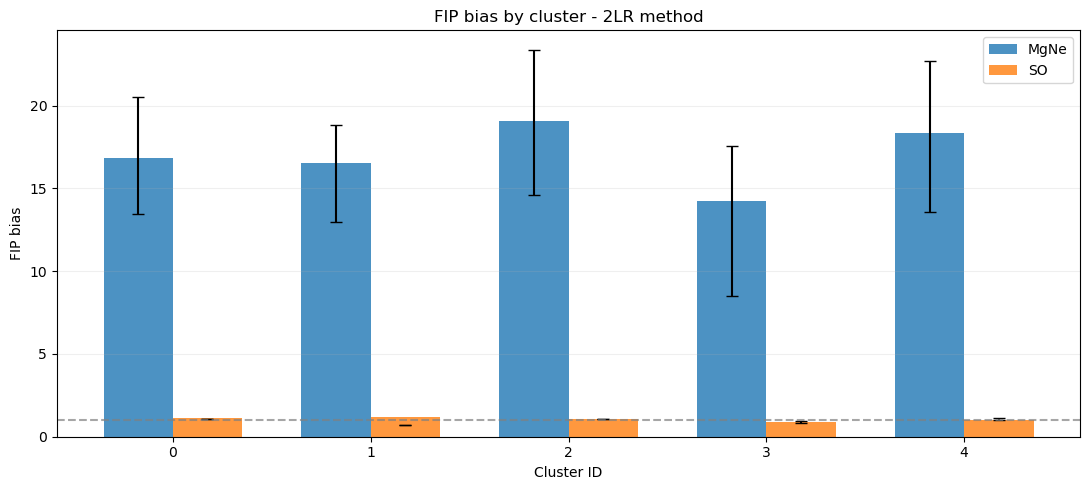

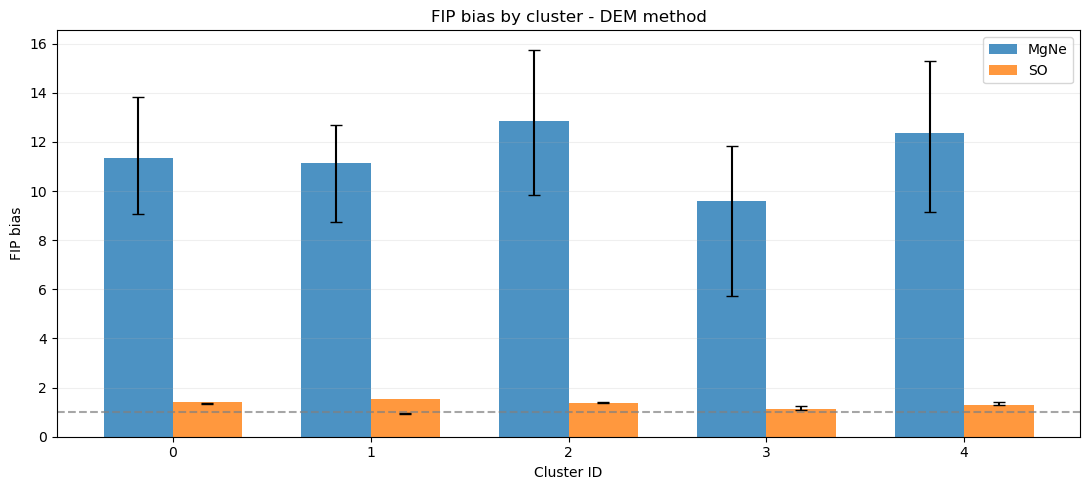

In [24]:
plot_cluster_fip(FIP_2LR_mean, FIP_2LR_p25, FIP_2LR_p75, method="2LR")
plot_cluster_fip(FIP_DEM_mean, FIP_DEM_p25, FIP_DEM_p75, method="DEM")